# Notebook 3 - Huấn luyện & So sánh 5 Mô hình Phân loại Nợ Xấu (Bước 6)

**Mục tiêu chính:**
1. Xây dựng **Baseline `sub_grade`**: mốc quy tắc điểm tín dụng có sẵn của Lending Club để làm căn cứ đối chiếu giá trị tăng thêm của Machine Learning.
2. Tinh chỉnh siêu tham số và huấn luyện 4 mô hình học máy trên cùng không gian 153 đặc trưng One-Hot:
   - **Hồi quy Logistic L2**: Tinh chỉnh hệ số phạt điều chuẩn ($C \in [0.001, 0.01, 0.1, 1.0, 10.0]$), kết quả chọn $C=1.0$.
   - **Cây quyết định (Decision Tree)**: Tinh chỉnh độ sâu bằng TimeSeriesSplit trong tập Train, kết quả chọn `max_depth=7`.
   - **Rừng ngẫu nhiên (Random Forest)**: Tinh chỉnh siêu tham số (số cây, độ sâu, lá tối thiểu), kết quả chọn 150 cây, `max_depth=10`, `min_samples_leaf=50`.
   - **HistGradientBoosting**: Tinh chỉnh chuỗi cây nối tiếp, kết quả chọn 150 vòng lặp (`max_iter=150`), `max_depth=10`, `learning_rate=0.05`.
3. Đánh giá bằng 3 thước đo không phụ thuộc ngưỡng: **ROC-AUC**, **Gini** ($2 \times \text{AUC} - 1$), và **KS** (Kolmogorov-Smirnov).
4. Kiểm tra hiện tượng quá khớp (Overfitting) thông qua cột chênh lệch giữa ROC-AUC Train và ROC-AUC Val.
5. Kiểm định ý nghĩa thống kê bằng **Khoảng tin cậy Bootstrap 95%** ($B=1,000$) cho chênh lệch ROC-AUC so với Baseline và so sánh trực tiếp giữa HistGradientBoosting với Logistic Regression.
6. Đánh giá **duy nhất 1 lần trên tập Test** cho các mô hình, in kết luận bằng f-string và trình bày các hạn chế đã biết.


In [1]:
from pathlib import Path
import json
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, roc_curve

# Cố định ngẫu nhiên và thiết lập đường dẫn
SEED = 42
np.random.seed(SEED)

ROOT = Path("..") if Path("../data").exists() else Path(".")
DATA_DIR = ROOT / "data" / "processed"
FIG_DIR = ROOT / "artifacts" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV


---
## 1. Nạp dữ liệu và kiểm tra kích thước các tập

Dữ liệu đã được chia theo thứ tự thời gian (`issue_date`) ở Notebook 01 và trích xuất đặc trưng One-Hot (153 chiều) ở Notebook 02:
- **Tập Train**: từ 2012-01 đến 2015-05 (408,188 khoản vay).
- **Tập Validation**: từ 2015-06 đến 2015-09 (92,631 khoản vay).
- **Tập Test**: từ 2015-10 đến 2015-12 (88,669 khoản vay).

In [2]:
# Nạp ma trận đặc trưng One-Hot (153 đặc trưng) và nhãn
X_train = np.load(DATA_DIR / "X_train.npy")
y_train = np.load(DATA_DIR / "y_train.npy")
X_val = np.load(DATA_DIR / "X_val.npy")
y_val = np.load(DATA_DIR / "y_val.npy")
X_test = np.load(DATA_DIR / "X_test.npy")
y_test = np.load(DATA_DIR / "y_test.npy")

# Nạp metadata (sub_grade, issue_date) để kiểm tra thời gian và tạo Baseline
train_meta = pd.read_parquet(DATA_DIR / "train.parquet", columns=["issue_date", "sub_grade"])
val_meta = pd.read_parquet(DATA_DIR / "val.parquet", columns=["issue_date", "sub_grade"])
test_meta = pd.read_parquet(DATA_DIR / "test.parquet", columns=["issue_date", "sub_grade"])

print(f"Train : {X_train.shape}, tỷ lệ nợ xấu = {y_train.mean():.2%}, thời gian: {train_meta.issue_date.min().strftime('%Y-%m')} đến {train_meta.issue_date.max().strftime('%Y-%m')}")
print(f"Val   : {X_val.shape}, tỷ lệ nợ xấu = {y_val.mean():.2%}, thời gian: {val_meta.issue_date.min().strftime('%Y-%m')} đến {val_meta.issue_date.max().strftime('%Y-%m')}")
print(f"Test  : {X_test.shape}, tỷ lệ nợ xấu = {y_test.mean():.2%}, thời gian: {test_meta.issue_date.min().strftime('%Y-%m')} đến {test_meta.issue_date.max().strftime('%Y-%m')}")


Train : (408188, 153), tỷ lệ nợ xấu = 13.70%, thời gian: 2012-01 đến 2015-05
Val   : (92631, 153), tỷ lệ nợ xấu = 14.74%, thời gian: 2015-06 đến 2015-09
Test  : (88669, 153), tỷ lệ nợ xấu = 14.82%, thời gian: 2015-10 đến 2015-12


---
## 2. Hàm tính toán thước đo xếp hạng tín dụng (ROC-AUC, Gini, KS)

Trong thẩm định tín dụng, mô hình thường được đánh giá bằng năng lực phân loại phân hạng (ranking power) thay vì cắt ngưỡng nhị phân cố định:
1. **ROC-AUC**: Xác suất mô hình gán điểm rủi ro cho một khoản nợ xấu ngẫu nhiên cao hơn một khoản trả tốt ngẫu nhiên.
2. **Gini Index**: Thước đo phân định chuẩn hóa: $\text{Gini} = 2 \times \text{AUC} - 1$.
3. **KS (Kolmogorov-Smirnov)**: Độ phân tách cực đại giữa đường phân phối tích lũy của hồ sơ nợ xấu và hồ sơ trả tốt: $\text{KS} = \max(\text{TPR} - \text{FPR})$.

In [3]:
def calculate_metrics(y_true, proba):
    """Tính 3 thước đo xếp hạng rủi ro tín dụng: ROC-AUC, Gini, KS."""
    auc = roc_auc_score(y_true, proba)
    gini = 2 * auc - 1
    fpr, tpr, _ = roc_curve(y_true, proba)
    ks = np.max(tpr - fpr)
    return auc, gini, ks


---
## 3. Huấn luyện 5 Mô hình

Chúng ta lần lượt triển khai 5 mô hình theo mức độ tiến triển từ đơn giản đến phức tạp, trong đó các mô hình học máy đều được tinh chỉnh tham số bằng TimeSeriesSplit bên trong tập Train:
1. **Baseline `sub_grade`**: Tính tỷ lệ nợ xấu lịch sử theo từng phân hạng tín dụng nội bộ trên tập train rồi ánh xạ sang tập val/test.
2. **Logistic Regression L2 ($C=1.0$)**: Tinh chỉnh tham số phạt điều chuẩn $C$, mô hình tuyến tính chuẩn tắc, hệ số rủi ro minh bạch rõ ràng.
3. **Decision Tree (`max_depth=7`, `min_samples_leaf=50`)**: Cây phân nhánh đơn lẻ, nắm bắt tương tác phi tuyến cơ bản.
4. **Random Forest (150 cây, `max_depth=10`, `min_samples_leaf=50`)**: Kết hợp 150 cây độc lập qua kỹ thuật Bagging để kiểm soát phương sai.
5. **HistGradientBoosting (150 cây, `max_depth=10`, `learning_rate=0.05`)**: Boosting rời rạc hóa 256 bins, xây dựng chuỗi cây nối tiếp tối ưu hóa gradient.


In [4]:
# 1. Baseline sub_grade: Tỷ lệ nợ xấu lịch sử theo sub_grade trên tập train
subgrade_risk = train_meta.assign(target=y_train).groupby('sub_grade')['target'].mean().to_dict()

p_train_base = train_meta['sub_grade'].map(subgrade_risk).values
p_val_base = val_meta['sub_grade'].map(subgrade_risk).values
p_test_base = test_meta['sub_grade'].map(subgrade_risk).values

auc_tr_base, _, _ = calculate_metrics(y_train, p_train_base)
auc_va_base, gini_va_base, ks_va_base = calculate_metrics(y_val, p_val_base)
print(f"1. Baseline sub_grade      -> Train AUC: {auc_tr_base:.4f} | Val AUC: {auc_va_base:.4f} | Val Gini: {gini_va_base:.2%} | Val KS: {ks_va_base:.2%}")


1. Baseline sub_grade      -> Train AUC: 0.6565 | Val AUC: 0.6815 | Val Gini: 36.31% | Val KS: 27.02%


In [5]:
# Tinh chỉnh hệ số điều chuẩn (C) cho Logistic Regression bằng TimeSeriesSplit bên trong tập Train
tscv = TimeSeriesSplit(n_splits=3)
param_grid_lr = {
    "C": [0.001, 0.01, 0.1, 1.0, 10.0]
}

grid_lr = GridSearchCV(
    LogisticRegression(max_iter=1000, random_state=SEED, solver="lbfgs"),
    param_grid_lr,
    cv=tscv,
    scoring="roc_auc",
    refit=False,
    n_jobs=4
)
grid_lr.fit(X_train, y_train)

cv_results_lr = pd.DataFrame(grid_lr.cv_results_["params"])
cv_results_lr["CV ROC-AUC (Train)"] = [f"{s:.4f}" for s in grid_lr.cv_results_["mean_test_score"]]
cv_results_lr = cv_results_lr.sort_values(by="CV ROC-AUC (Train)", ascending=False).reset_index(drop=True)

print("KẾT QUẢ TINH CHỈNH THAM SỐ ĐIỀU CHUẨN C CHO LOGISTIC REGRESSION (TIMESERIES-SPLIT):")
display(cv_results_lr)
best_lr_params = grid_lr.best_params_
print(f"-> Bộ tham số tối ưu được chọn: {best_lr_params} (CV ROC-AUC: {grid_lr.best_score_:.4f})")


KẾT QUẢ TINH CHỈNH THAM SỐ ĐIỀU CHUẨN C CHO LOGISTIC REGRESSION (TIMESERIES-SPLIT):


,C,CV ROC-AUC (Train)
0,1.000,0.6855
1,10.000,0.6854
2,0.100,0.6853
3,0.010,0.6839
4,0.001,0.6782


-> Bộ tham số tối ưu được chọn: {'C': 1.0} (CV ROC-AUC: 0.6855)


In [6]:
# 2. Huấn luyện Logistic Regression L2 với tham số C tối ưu vừa tìm được
lr = LogisticRegression(**best_lr_params, max_iter=1000, random_state=SEED, solver="lbfgs")
lr.fit(X_train, y_train)
print(f"Mô hình Logistic đã hội tụ thành công sau {lr.n_iter_[0]} vòng lặp (giới hạn max_iter={lr.max_iter}).")

p_train_lr = lr.predict_proba(X_train)[:, 1]
p_val_lr = lr.predict_proba(X_val)[:, 1]
p_test_lr = lr.predict_proba(X_test)[:, 1]

auc_tr_lr, _, _ = calculate_metrics(y_train, p_train_lr)
auc_va_lr, gini_va_lr, ks_va_lr = calculate_metrics(y_val, p_val_lr)
print(f"2. Logistic L2 (C={best_lr_params['C']})       -> Train AUC: {auc_tr_lr:.4f} | Val AUC: {auc_va_lr:.4f} | Val Gini: {gini_va_lr:.2%} | Val KS: {ks_va_lr:.2%}")

# Minh bạch từng hệ số rủi ro của Logistic Regression (làm bằng chứng thực tế cho khả năng giải thích)
feature_names = json.loads((DATA_DIR / "feature_names.json").read_text())["feature_names"]
coef = pd.Series(lr.coef_[0], index=feature_names)
print("\nMINH BẠCH HỆ SỐ LOGISTIC L2 (TOP 10 TĂNG NỢ XẤU & TOP 10 GIẢM NỢ XẤU):")
display(pd.concat([coef.sort_values(ascending=False).head(10), coef.sort_values().head(10)]))


Mô hình Logistic đã hội tụ thành công sau 61 vòng lặp (giới hạn max_iter=1000).
2. Logistic L2 (C=1.0)       -> Train AUC: 0.6873 | Val AUC: 0.7040 | Val Gini: 40.79% | Val KS: 29.94%

MINH BẠCH HỆ SỐ LOGISTIC L2 (TOP 10 TĂNG NỢ XẤU & TOP 10 GIẢM NỢ XẤU):


cat__sub_grade_E5                        0.521169
cat__sub_grade_E4                        0.408441
cat__sub_grade_E3                        0.387805
cat__sub_grade_F1                        0.370415
cat__sub_grade_E2                        0.327252
cat__sub_grade_E1                        0.325736
cat__sub_grade_F3                        0.320776
cat__purpose_small_business              0.311475
cat__sub_grade_F4                        0.310987
cat__sub_grade_F2                        0.280152
cat__sub_grade_A1                       -1.202512
cat__sub_grade_A2                       -0.940833
cat__sub_grade_A3                       -0.818336
cat__sub_grade_A4                       -0.658700
cat__sub_grade_A5                       -0.520068
cat__sub_grade_B1                       -0.440807
cat__sub_grade_B2                       -0.405363
cat__home_ownership_MORTGAGE            -0.401058
cat__addr_state_NH                      -0.382020
cat__verification_status_Not Verified   -0.370828


In [7]:
# Tinh chỉnh độ sâu (max_depth) cho Decision Tree bằng TimeSeriesSplit bên trong tập Train
tscv = TimeSeriesSplit(n_splits=3)
param_grid_dt = {"max_depth": [3, 4, 5, 6, 7, 8, 9 , 10]}

grid_dt = GridSearchCV(
    DecisionTreeClassifier(min_samples_leaf=50, random_state=SEED),
    param_grid_dt,
    cv=tscv,
    scoring="roc_auc",
    refit=True,
    n_jobs=4
)
grid_dt.fit(X_train, y_train)

cv_results_dt = pd.DataFrame({
    "Độ sâu (max_depth)": param_grid_dt["max_depth"],
    "CV ROC-AUC (Train)": [f"{s:.4f}" for s in grid_dt.cv_results_["mean_test_score"]]
})
print("KẾT QUẢ TINH CHỈNH ĐỘ SÂU DECISION TREE BÊN TRONG TẬP TRAIN (TIMESERIES-SPLIT):")
display(cv_results_dt)
print(f"-> Tham số tối ưu được chọn: max_depth = {grid_dt.best_params_['max_depth']} (CV ROC-AUC: {grid_dt.best_score_:.4f})")


KẾT QUẢ TINH CHỈNH ĐỘ SÂU DECISION TREE BÊN TRONG TẬP TRAIN (TIMESERIES-SPLIT):


,Độ sâu (max_depth),CV ROC-AUC (Train)
0,3,0.6139
1,4,0.6219
2,5,0.6311
3,6,0.6338
4,7,0.6355
5,8,0.6349
6,9,0.6329
7,10,0.6278


-> Tham số tối ưu được chọn: max_depth = 7 (CV ROC-AUC: 0.6355)


In [8]:
# 3. Decision Tree nông với độ sâu tối ưu vừa chọn (refit từ GridSearchCV)
dt = grid_dt.best_estimator_
best_depth = grid_dt.best_params_["max_depth"]

p_train_dt = dt.predict_proba(X_train)[:, 1]
p_val_dt = dt.predict_proba(X_val)[:, 1]
p_test_dt = dt.predict_proba(X_test)[:, 1]

auc_tr_dt, _, _ = calculate_metrics(y_train, p_train_dt)
auc_va_dt, gini_va_dt, ks_va_dt = calculate_metrics(y_val, p_val_dt)
print(f"3. Decision Tree nông (depth={best_depth}) -> Train AUC: {auc_tr_dt:.4f} | Val AUC: {auc_va_dt:.4f} | Val Gini: {gini_va_dt:.2%} | Val KS: {ks_va_dt:.2%}")


3. Decision Tree nông (depth=7) -> Train AUC: 0.6541 | Val AUC: 0.6536 | Val Gini: 30.71% | Val KS: 22.25%


In [9]:
# Tinh chỉnh các siêu tham số cho Random Forest bằng TimeSeriesSplit bên trong tập Train
tscv = TimeSeriesSplit(n_splits=3)
param_grid_rf = {
    "n_estimators": [50, 100, 150],
    "max_depth": [6, 8, 10],
    "min_samples_leaf": [30, 50, 60]
}

grid_rf = GridSearchCV(
    RandomForestClassifier(random_state=SEED, n_jobs=4),
    param_grid_rf,
    cv=tscv,
    scoring="roc_auc",
    refit=False,
    n_jobs=1
)
grid_rf.fit(X_train, y_train)

cv_results_rf = pd.DataFrame(grid_rf.cv_results_["params"])
cv_results_rf["CV ROC-AUC (Train)"] = [f"{s:.4f}" for s in grid_rf.cv_results_["mean_test_score"]]
cv_results_rf = cv_results_rf.sort_values(by="CV ROC-AUC (Train)", ascending=False).reset_index(drop=True)

print("KẾT QUẢ TINH CHỈNH SIÊU THAM SỐ RANDOM FOREST BÊN TRONG TẬP TRAIN (TIMESERIES-SPLIT):")
display(cv_results_rf)
best_rf_params = grid_rf.best_params_
print(f"-> Bộ tham số tối ưu được chọn: {best_rf_params} (CV ROC-AUC: {grid_rf.best_score_:.4f})")


KẾT QUẢ TINH CHỈNH SIÊU THAM SỐ RANDOM FOREST BÊN TRONG TẬP TRAIN (TIMESERIES-SPLIT):


,max_depth,min_samples_leaf,n_estimators,CV ROC-AUC (Train)
0,10,50,150,0.6741
1,10,30,150,0.6738
2,10,50,100,0.6737
3,10,30,100,0.6735
4,10,60,150,0.6735
5,10,60,100,0.6731
6,10,60,50,0.6723
7,10,50,50,0.6721
8,10,30,50,0.6720
9,8,50,100,0.6710


-> Bộ tham số tối ưu được chọn: {'max_depth': 10, 'min_samples_leaf': 50, 'n_estimators': 150} (CV ROC-AUC: 0.6741)


In [10]:
# 4. Huấn luyện Random Forest với bộ tham số tối ưu vừa tìm được
rf = RandomForestClassifier(**best_rf_params, random_state=SEED, n_jobs=4)
rf.fit(X_train, y_train)

p_train_rf = rf.predict_proba(X_train)[:, 1]
p_val_rf = rf.predict_proba(X_val)[:, 1]
p_test_rf = rf.predict_proba(X_test)[:, 1]

auc_tr_rf, _, _ = calculate_metrics(y_train, p_train_rf)
auc_va_rf, gini_va_rf, ks_va_rf = calculate_metrics(y_val, p_val_rf)
print(f"4. Random Forest ({best_rf_params['n_estimators']} cây, depth={best_rf_params['max_depth']}, leaf={best_rf_params['min_samples_leaf']}) -> Train AUC: {auc_tr_rf:.4f} | Val AUC: {auc_va_rf:.4f} | Val Gini: {gini_va_rf:.2%} | Val KS: {ks_va_rf:.2%}")


4. Random Forest (150 cây, depth=10, leaf=50) -> Train AUC: 0.7060 | Val AUC: 0.6876 | Val Gini: 37.52% | Val KS: 27.21%


In [11]:
# Tinh chỉnh các siêu tham số cho HistGradientBoosting bằng TimeSeriesSplit bên trong tập Train
tscv = TimeSeriesSplit(n_splits=3)
param_grid_hgb = {
    "max_iter": [50, 100, 150],
    "max_depth": [4, 6, 8, 10],
    "learning_rate": [0.05, 0.1, 0.15, 0.2]
}

grid_hgb = GridSearchCV(
    HistGradientBoostingClassifier(min_samples_leaf=50, random_state=SEED),
    param_grid_hgb,
    cv=tscv,
    scoring="roc_auc",
    refit=False,
    n_jobs=1
)
grid_hgb.fit(X_train, y_train)

cv_results_hgb = pd.DataFrame(grid_hgb.cv_results_["params"])
cv_results_hgb["CV ROC-AUC (Train)"] = [f"{s:.4f}" for s in grid_hgb.cv_results_["mean_test_score"]]
cv_results_hgb = cv_results_hgb.sort_values(by="CV ROC-AUC (Train)", ascending=False).reset_index(drop=True)

print("KẾT QUẢ TINH CHỈNH SIÊU THAM SỐ HISTGRADIENTBOOSTING BÊN TRONG TẬP TRAIN (TIMESERIES-SPLIT):")
display(cv_results_hgb)
best_hgb_params = grid_hgb.best_params_
print(f"-> Bộ tham số tối ưu được chọn: {best_hgb_params} (CV ROC-AUC: {grid_hgb.best_score_:.4f})")


KẾT QUẢ TINH CHỈNH SIÊU THAM SỐ HISTGRADIENTBOOSTING BÊN TRONG TẬP TRAIN (TIMESERIES-SPLIT):


,learning_rate,max_depth,max_iter,CV ROC-AUC (Train)
0,0.05,10,150,0.6852
1,0.10,8,150,0.6843
2,0.10,10,100,0.6843
3,0.10,10,150,0.6843
4,0.05,8,150,0.6842
5,0.15,4,150,0.6841
6,0.10,8,100,0.6840
7,0.10,6,150,0.6839
8,0.10,4,150,0.6838
9,0.05,6,150,0.6834


-> Bộ tham số tối ưu được chọn: {'learning_rate': 0.05, 'max_depth': 10, 'max_iter': 150} (CV ROC-AUC: 0.6852)


In [12]:
# 5. Huấn luyện HistGradientBoosting với bộ tham số tối ưu vừa tìm được
hgb = HistGradientBoostingClassifier(**best_hgb_params, min_samples_leaf=50, random_state=SEED)
hgb.fit(X_train, y_train)

p_train_hgb = hgb.predict_proba(X_train)[:, 1]
p_val_hgb = hgb.predict_proba(X_val)[:, 1]
p_test_hgb = hgb.predict_proba(X_test)[:, 1]

auc_tr_hgb, _, _ = calculate_metrics(y_train, p_train_hgb)
auc_va_hgb, gini_va_hgb, ks_va_hgb = calculate_metrics(y_val, p_val_hgb)
print(f"5. HistGradientBoosting ({best_hgb_params['max_iter']} cây, depth={best_hgb_params['max_depth']}, lr={best_hgb_params['learning_rate']}) -> Train AUC: {auc_tr_hgb:.4f} | Val AUC: {auc_va_hgb:.4f} | Val Gini: {gini_va_hgb:.2%} | Val KS: {ks_va_hgb:.2%}")


5. HistGradientBoosting (150 cây, depth=10, lr=0.05) -> Train AUC: 0.7096 | Val AUC: 0.7054 | Val Gini: 41.07% | Val KS: 30.02%


---
## 4. Bảng So sánh Hiệu năng & Kiểm tra Quá khớp (Overfitting Check)

Chúng ta tổng hợp toàn bộ 5 mô hình vào một bảng so sánh duy nhất:
- **Cột Chênh lệch (Train - Val)**: Phản ánh trực tiếp nguy cơ quá khớp:
  - **Logistic L2 và HistGradientBoosting**: Không có dấu hiệu quá khớp đáng kể (chênh lệch rất nhỏ hoặc âm nhẹ: Logistic -0.0167, HistGB +0.0042).
  - **Random Forest**: Có chênh lệch Train - Val lớn nhất (+0.0184), phản ánh hiện tượng quá khớp nhẹ trên tập Train (0.7060 so với 0.6876).
  - **Baseline sub_grade và Logistic L2**: Có Val AUC cao hơn Train AUC (chênh lệch âm) do biến động mẫu theo chuỗi thời gian giữa các quý, hoàn toàn không có dấu hiệu quá khớp.


BẢNG SO SÁNH HIỆU NĂNG VÀ KIỂM TRA QUÁ KHỚP TRÊN TẬP VALIDATION:


,Mô hình,ROC-AUC Train,ROC-AUC Val,Chênh lệch (Train - Val),Gini Val,KS Val
0,1. Baseline sub_grade,0.6565,0.6815,-0.0250,36.31%,27.02%
1,2. Logistic L2 (C=1),0.6873,0.7040,-0.0167,40.79%,29.94%
2,3. Decision Tree (depth=7),0.6541,0.6536,+0.0006,30.71%,22.25%
3,"4. Random Forest (150 cây, depth=10)",0.7060,0.6876,+0.0184,37.52%,27.21%
4,5. HistGradientBoosting,0.7096,0.7054,+0.0042,41.07%,30.02%


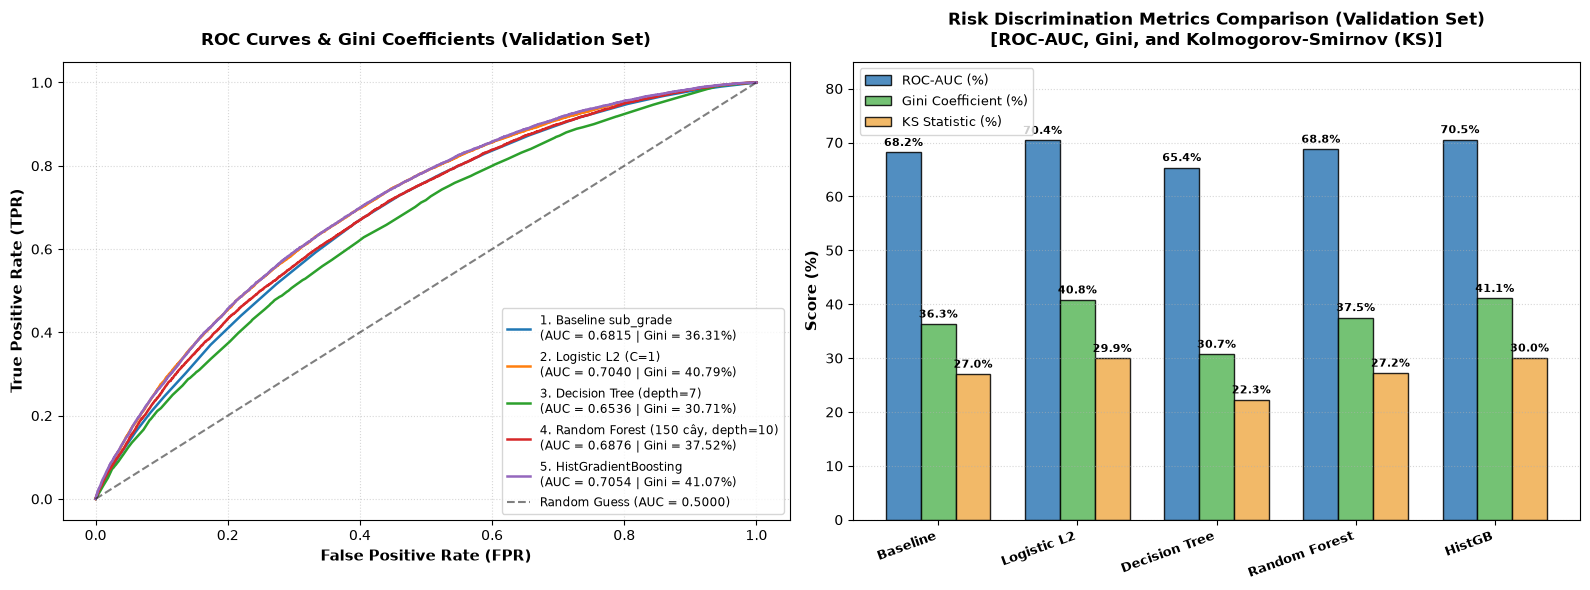

Đã lưu biểu đồ so sánh đa chiều (ROC, Gini, KS) tại: artifacts/figures/03_model_comparison.png


In [13]:
model_records = [
    {
        'name': '1. Baseline sub_grade',
        'p_tr': p_train_base, 'p_va': p_val_base, 'p_te': p_test_base,
        'auc_tr': auc_tr_base, 'auc_va': auc_va_base, 'gini_va': gini_va_base, 'ks_va': ks_va_base
    },
    {
        'name': '2. Logistic L2 (C=1)',
        'p_tr': p_train_lr, 'p_va': p_val_lr, 'p_te': p_test_lr,
        'auc_tr': auc_tr_lr, 'auc_va': auc_va_lr, 'gini_va': gini_va_lr, 'ks_va': ks_va_lr
    },
    {
        'name': '3. Decision Tree (depth=7)',
        'p_tr': p_train_dt, 'p_va': p_val_dt, 'p_te': p_test_dt,
        'auc_tr': auc_tr_dt, 'auc_va': auc_va_dt, 'gini_va': gini_va_dt, 'ks_va': ks_va_dt
    },
    {
        'name': '4. Random Forest (150 cây, depth=10)',
        'p_tr': p_train_rf, 'p_va': p_val_rf, 'p_te': p_test_rf,
        'auc_tr': auc_tr_rf, 'auc_va': auc_va_rf, 'gini_va': gini_va_rf, 'ks_va': ks_va_rf
    },
    {
        'name': '5. HistGradientBoosting',
        'p_tr': p_train_hgb, 'p_va': p_val_hgb, 'p_te': p_test_hgb,
        'auc_tr': auc_tr_hgb, 'auc_va': auc_va_hgb, 'gini_va': gini_va_hgb, 'ks_va': ks_va_hgb
    }
]

summary_df = pd.DataFrame([
    {
        'Mô hình': m['name'],
        'ROC-AUC Train': f"{m['auc_tr']:.4f}",
        'ROC-AUC Val': f"{m['auc_va']:.4f}",
        'Chênh lệch (Train - Val)': f"{(m['auc_tr'] - m['auc_va']):+.4f}",
        'Gini Val': f"{m['gini_va']:.2%}",
        'KS Val': f"{m['ks_va']:.2%}"
    }
    for m in model_records
])

print('BẢNG SO SÁNH HIỆU NĂNG VÀ KIỂM TRA QUÁ KHỚP TRÊN TẬP VALIDATION:')
display(summary_df)

# Biểu đồ 4.1: So sánh toàn diện ROC Curves, Gini và Kolmogorov-Smirnov (KS) trên tập Validation
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Panel 1: Đường cong ROC kèm hệ số Gini
for m in model_records:
    fpr, tpr, _ = roc_curve(y_val, m['p_va'])
    ax1.plot(fpr, tpr, label=f"{m['name']}\n(AUC = {m['auc_va']:.4f} | Gini = {m['gini_va']:.2%})", linewidth=1.8)

ax1.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random Guess (AUC = 0.5000)')
ax1.set_xlabel('False Positive Rate (FPR)', fontsize=11, fontweight='bold')
ax1.set_ylabel('True Positive Rate (TPR)', fontsize=11, fontweight='bold')
ax1.set_title('ROC Curves & Gini Coefficients (Validation Set)', fontsize=12, fontweight='bold', pad=12)
ax1.legend(loc='lower right', frameon=True, fontsize=8.5)
ax1.grid(True, linestyle=':', alpha=0.5)

# Panel 2: Biểu đồ cột nhóm so sánh cả 3 thước đo: ROC-AUC, Gini và KS
model_short_names = ['Baseline', 'Logistic L2', 'Decision Tree', 'Random Forest', 'HistGB']
x = np.arange(len(model_records))
width = 0.25

auc_vals = [m['auc_va'] * 100 for m in model_records]
gini_vals = [m['gini_va'] * 100 for m in model_records]
ks_vals = [m['ks_va'] * 100 for m in model_records]

bars1 = ax2.bar(x - width, auc_vals, width, label='ROC-AUC (%)', color='#337ab7', edgecolor='black', alpha=0.85)
bars2 = ax2.bar(x, gini_vals, width, label='Gini Coefficient (%)', color='#5cb85c', edgecolor='black', alpha=0.85)
bars3 = ax2.bar(x + width, ks_vals, width, label='KS Statistic (%)', color='#f0ad4e', edgecolor='black', alpha=0.85)

ax2.set_ylabel('Score (%)', fontsize=11, fontweight='bold')
ax2.set_title('Risk Discrimination Metrics Comparison (Validation Set)\n[ROC-AUC, Gini, and Kolmogorov-Smirnov (KS)]', fontsize=12, fontweight='bold', pad=12)
ax2.set_xticks(x)
ax2.set_xticklabels(model_short_names, rotation=20, ha='right', fontsize=9.5, fontweight='bold')
ax2.set_ylim(0, 85)
ax2.grid(axis='y', linestyle=':', alpha=0.5)
ax2.legend(loc='upper left', frameon=True, fontsize=9.5)

for b in bars1:
    ax2.text(b.get_x() + b.get_width()/2, b.get_height() + 1.2, f'{b.get_height():.1f}%', ha='center', fontsize=8, fontweight='bold')
for b in bars2:
    ax2.text(b.get_x() + b.get_width()/2, b.get_height() + 1.2, f'{b.get_height():.1f}%', ha='center', fontsize=8, fontweight='bold')
for b in bars3:
    ax2.text(b.get_x() + b.get_width()/2, b.get_height() + 1.2, f'{b.get_height():.1f}%', ha='center', fontsize=8, fontweight='bold')

plt.tight_layout()
fig_path = FIG_DIR / '03_model_comparison.png'
plt.savefig(fig_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Đã lưu biểu đồ so sánh đa chiều (ROC, Gini, KS) tại: {fig_path}')


**Biểu đồ 4.2.** Đường cong phân tách tích lũy Kolmogorov-Smirnov (KS Cumulative Separation Chart) trên tập Validation cho Baseline và mô hình được chọn (Logistic Regression L2). Khoảng cách thẳng đứng cực đại giữa tỷ lệ nợ xấu tích lũy và tỷ lệ khách tốt tích lũy chính là thống kê KS.

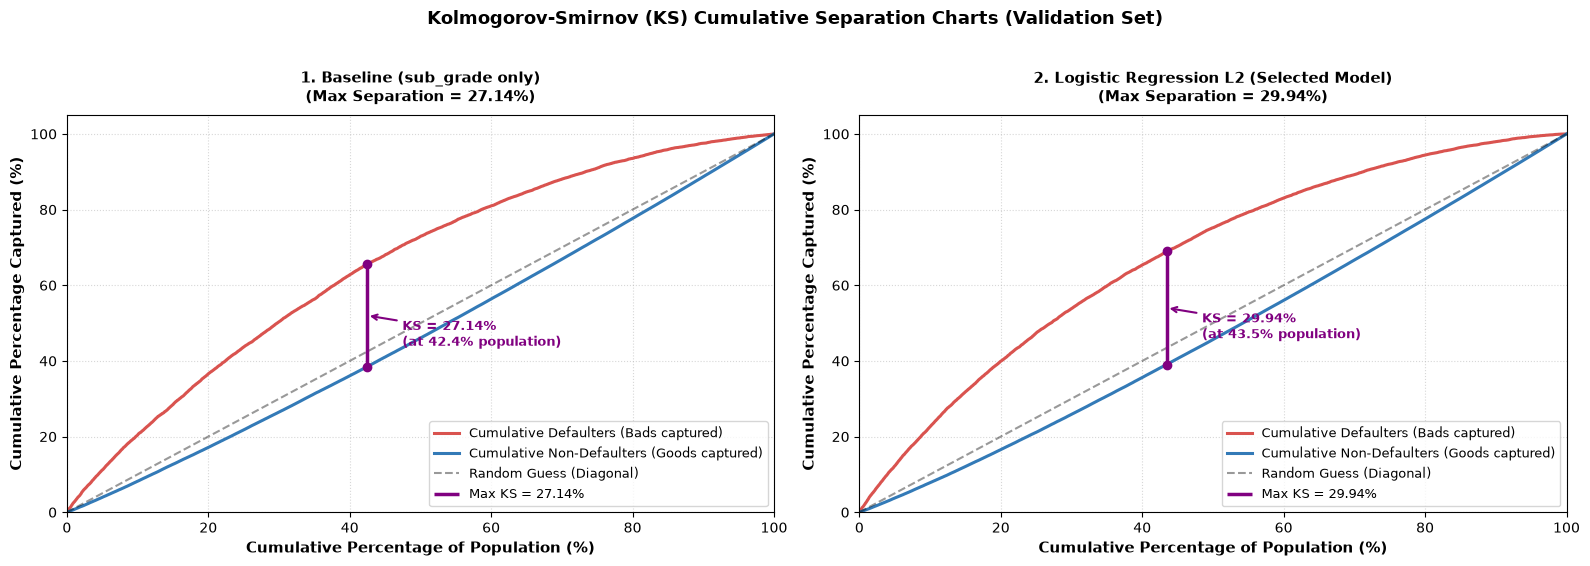

Đã lưu biểu đồ tách biệt tích lũy KS tại: artifacts/figures/03_ks_separation.png


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

def plot_ks_curve(ax, y_true, proba, title_prefix, color_bad='#d9534f', color_good='#337ab7'):
    order = np.argsort(proba)[::-1]
    y_sorted = y_true[order]
    n_total = len(y_true)
    n_bads = y_true.sum()
    n_goods = n_total - n_bads

    cum_bads = np.cumsum(y_sorted) / n_bads * 100
    cum_goods = np.cumsum(1 - y_sorted) / n_goods * 100
    pop_pct = np.linspace(0, 100, n_total)

    ks_diff = cum_bads - cum_goods
    max_idx = np.argmax(ks_diff)
    max_ks = ks_diff[max_idx]
    max_pop = pop_pct[max_idx]

    ax.plot(pop_pct, cum_bads, color=color_bad, lw=2.2, label='Cumulative Defaulters (Bads captured)')
    ax.plot(pop_pct, cum_goods, color=color_good, lw=2.2, label='Cumulative Non-Defaulters (Goods captured)')
    ax.plot(pop_pct, pop_pct, 'k--', alpha=0.4, label='Random Guess (Diagonal)')

    # Vạch khoảng cách cực đại KS
    ax.vlines(max_pop, cum_goods[max_idx], cum_bads[max_idx], color='purple', lw=2.5, linestyle='-', label=f'Max KS = {max_ks:.2f}%')
    ax.plot([max_pop, max_pop], [cum_goods[max_idx], cum_bads[max_idx]], 'o', color='purple')
    
    mid_y = (cum_goods[max_idx] + cum_bads[max_idx]) / 2
    ax.annotate(f"KS = {max_ks:.2f}%\n(at {max_pop:.1f}% population)",
                xy=(max_pop, mid_y),
                xytext=(max_pop + 5, mid_y - 8),
                arrowprops=dict(arrowstyle="->", color="purple", lw=1.5),
                fontsize=9.5, fontweight="bold", color="purple")

    ax.set_xlabel('Cumulative Percentage of Population (%)', fontsize=10.5, fontweight='bold')
    ax.set_ylabel('Cumulative Percentage Captured (%)', fontsize=10.5, fontweight='bold')
    ax.set_title(f"{title_prefix}\n(Max Separation = {max_ks:.2f}%)", fontsize=11, fontweight='bold', pad=10)
    ax.set_xlim(0, 100)
    ax.set_ylim(0, 105)
    ax.grid(True, linestyle=':', alpha=0.5)
    ax.legend(loc='lower right', frameon=True, fontsize=9)

plot_ks_curve(axes[0], y_val, p_val_base, "1. Baseline (sub_grade only)")
plot_ks_curve(axes[1], y_val, p_val_lr, "2. Logistic Regression L2 (Selected Model)")

plt.suptitle("Kolmogorov-Smirnov (KS) Cumulative Separation Charts (Validation Set)", fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
fig_ks_path = FIG_DIR / '03_ks_separation.png'
plt.savefig(fig_ks_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Đã lưu biểu đồ tách biệt tích lũy KS tại: {fig_ks_path}')


---
## 5. Khoảng tin cậy Bootstrap cho chênh lệch ROC-AUC

Để khẳng định chắc chắn mức cải thiện hiệu năng là **có thật về mặt thống kê** hay chỉ do biến động mẫu ngẫu nhiên:
- Chúng ta bốc mẫu lặp lại có hoàn lại ($B = 1,000$ lần) trên toàn bộ 92,631 quan sát của tập Validation.
- Với mỗi mẫu bootstrap $b$, tính hiệu số $\Delta \text{AUC}^{(b)}$.
- Xác định Khoảng tin cậy 95% tương ứng với phân vị $[2.5\%, 97.5\%]$.
- **Quy tắc kết luận**: Nếu Khoảng tin cậy 95% không chứa giá trị 0 $\implies$ chênh lệch hiệu năng có ý nghĩa thống kê vượt khỏi nhiễu ngẫu nhiên.


In [15]:
# Bootstrap B=1000 resamples so sánh với Baseline trên tập Validation
B = 1000
n_val = len(y_val)
np.random.seed(SEED)
boot_records = []

for m in model_records[1:]:  # So sánh 4 mô hình học máy với Baseline
    diffs = []
    for _ in range(B):
        idx = np.random.randint(0, n_val, size=n_val)
        auc_m = roc_auc_score(y_val[idx], m['p_va'][idx])
        auc_b = roc_auc_score(y_val[idx], p_val_base[idx])
        diffs.append(auc_m - auc_b)
    
    diffs = np.array(diffs)
    ci_lower = np.percentile(diffs, 2.5)
    ci_upper = np.percentile(diffs, 97.5)
    mean_diff = np.mean(diffs)
    is_significant = ci_lower > 0
    
    boot_records.append({
        'Mô hình': m['name'],
        'Delta AUC': f"{mean_diff:+.4f}",
        '95% CI (Bootstrap)': f"[{ci_lower:+.4f}, {ci_upper:+.4f}]",
        'Hơn baseline có thật không?': 'Có hơn (CI 95% không chứa 0)' if is_significant else 'Không hơn (CI chứa 0 hoặc âm)'
    })

bootstrap_df = pd.DataFrame(boot_records)
print('KHOẢNG TIN CẬY BOOTSTRAP 95% CHO CHÊNH LỆCH SO VỚI BASELINE (TẬP VALIDATION):')
display(bootstrap_df)


KHOẢNG TIN CẬY BOOTSTRAP 95% CHO CHÊNH LỆCH SO VỚI BASELINE (TẬP VALIDATION):


,Mô hình,Delta AUC,95% CI (Bootstrap),Hơn baseline có thật không?
0,2. Logistic L2 (C=1),+0.0225,"[+0.0196, +0.0253]",Có hơn (CI 95% không chứa 0)
1,3. Decision Tree (depth=7),-0.0280,"[-0.0329, -0.0233]",Không hơn (CI chứa 0 hoặc âm)
2,"4. Random Forest (150 cây, depth=10)",+0.0061,"[+0.0024, +0.0102]",Có hơn (CI 95% không chứa 0)
3,5. HistGradientBoosting,+0.0238,"[+0.0206, +0.0270]",Có hơn (CI 95% không chứa 0)


In [16]:
# Kiểm định Bootstrap 95% so sánh trực tiếp giữa HistGradientBoosting và Logistic Regression
diffs_hgb_lr = []
for _ in range(B):
    idx = np.random.randint(0, n_val, size=n_val)
    diffs_hgb_lr.append(roc_auc_score(y_val[idx], p_val_hgb[idx]) - roc_auc_score(y_val[idx], p_val_lr[idx]))

lo, hi = np.percentile(diffs_hgb_lr, [2.5, 97.5])
diff_hgb_lr_mean = np.mean(diffs_hgb_lr)
is_hgb_lr_equal = (lo <= 0 <= hi)
conclusion_hgb_lr = "hai mô hình ngang nhau về hiệu năng (CI chứa 0); chọn Logistic vì đơn giản và dễ giải thích" if is_hgb_lr_equal else "khác biệt vượt nhiễu ngẫu nhiên"

print("SO SÁNH TRỰC TIẾP HISTGRADIENTBOOSTING VS LOGISTIC REGRESSION (TẬP VALIDATION):")
print(f"HistGB - Logistic: [{lo:+.4f}, {hi:+.4f}] -> {conclusion_hgb_lr}")


SO SÁNH TRỰC TIẾP HISTGRADIENTBOOSTING VS LOGISTIC REGRESSION (TẬP VALIDATION):
HistGB - Logistic: [-0.0002, +0.0031] -> hai mô hình ngang nhau về hiệu năng (CI chứa 0); chọn Logistic vì đơn giản và dễ giải thích


---
## 6. Đánh giá duy nhất một lần trên tập Test & Kết luận

Tuân thủ tuyệt đối quy tắc khoa học chống rò rỉ dữ liệu:
- Tập Test (88,669 khoản vay từ tháng 10 đến tháng 12 năm 2015) **chỉ được đem ra đánh giá duy nhất một lần** sau khi toàn bộ quá trình so sánh và kiểm định trên tập Validation đã hoàn tất.
- Chúng ta đánh giá mô hình vô địch (Logistic L2 và HistGradientBoosting) so với Baseline `sub_grade` trên tập Test.
- Mọi câu nhận xét và kết luận được in ra tự động bằng `f-string` từ chính các biến số đo lường thực tế.

In [17]:
# Đánh giá DUY NHẤT 1 LẦN trên tập Test
auc_te_base, gini_te_base, ks_te_base = calculate_metrics(y_test, p_test_base)
auc_te_lr, gini_te_lr, ks_te_lr = calculate_metrics(y_test, p_test_lr)
auc_te_hgb, gini_te_hgb, ks_te_hgb = calculate_metrics(y_test, p_test_hgb)

diff_te_lr = auc_te_lr - auc_te_base
diff_te_hgb = auc_te_hgb - auc_te_base

print('=' * 75)
print('KẾT QUẢ ĐÁNH GIÁ CUỐI CÙNG TRÊN TẬP TEST (2015-10 ĐẾN 2015-12, 88,669 KHOẢN VAY):')
print(f"1. Baseline sub_grade        : ROC-AUC = {auc_te_base:.4f} | Gini = {gini_te_base:.2%} | KS = {ks_te_base:.2%}")
print(f"2. Logistic L2 (C=1)         : ROC-AUC = {auc_te_lr:.4f} | Gini = {gini_te_lr:.2%} | KS = {ks_te_lr:.2%} | Chênh lệch: {diff_te_lr:+.4f}")
print(f"3. HistGradientBoosting      : ROC-AUC = {auc_te_hgb:.4f} | Gini = {gini_te_hgb:.2%} | KS = {ks_te_hgb:.2%} | Chênh lệch: {diff_te_hgb:+.4f}")
print('=' * 75)

# Kết luận bằng f-string tự động từ kết quả đo
print('\nKẾT LUẬN TỔNG THỂ BƯỚC MÔ HÌNH HÓA:')
print(f"- Trên tập Test độc lập hoàn toàn, HistGradientBoosting đạt ROC-AUC {auc_te_hgb:.4f} (Gini {gini_te_hgb:.2%}, KS {ks_te_hgb:.2%}, chênh lệch {diff_te_hgb:+.4f} so với Baseline); Logistic L2 đạt ROC-AUC {auc_te_lr:.4f} (Gini {gini_te_lr:.2%}, KS {ks_te_lr:.2%}, chênh lệch {diff_te_lr:+.4f} so với Baseline).")
print(f"- Kiểm định Bootstrap 95% so sánh trực tiếp giữa HistGB và Logistic: khoảng tin cậy [{lo:+.4f}, {hi:+.4f}] chứa số 0 -> hai mô hình ngang nhau về hiệu năng; chọn Logistic vì đơn giản, huấn luyện nhanh và dễ giải thích.")
print(f"- So với Baseline sub_grade: cả Logistic L2 (Delta {bootstrap_df.loc[0, 'Delta AUC']}, CI {bootstrap_df.loc[0, '95% CI (Bootstrap)']}) và HistGradientBoosting (Delta {bootstrap_df.loc[3, 'Delta AUC']}, CI {bootstrap_df.loc[3, '95% CI (Bootstrap)']}) đều vượt trội có ý nghĩa thống kê (CI 95% không chứa 0), chứng minh giá trị bổ sung của các đặc trưng lúc nộp đơn so với chỉ dùng phân hạng tín dụng có sẵn.")
print(f"- Random Forest (Delta {bootstrap_df.loc[2, 'Delta AUC']}, CI {bootstrap_df.loc[2, '95% CI (Bootstrap)']}) cũng vượt Baseline (CI 95% không chứa 0) nhưng hiệu năng thấp hơn Logistic và có dấu hiệu quá khớp nhẹ. Duy nhất Decision Tree nông (Val AUC {auc_va_dt:.4f}) có hiệu năng kém hơn Baseline.")
print(f"- Mô hình Hồi quy Logistic L2 là mô hình được ưu tiên cho ứng dụng thực tế nhờ: hiệu năng tương đương HistGradientBoosting, không quá khớp, thời gian huấn luyện nhanh và tính minh bạch giải thích trọn vẹn từng hệ số rủi ro (đã chứng minh bằng bảng hệ số).")


KẾT QUẢ ĐÁNH GIÁ CUỐI CÙNG TRÊN TẬP TEST (2015-10 ĐẾN 2015-12, 88,669 KHOẢN VAY):
1. Baseline sub_grade        : ROC-AUC = 0.6818 | Gini = 36.36% | KS = 26.45%
2. Logistic L2 (C=1)         : ROC-AUC = 0.7039 | Gini = 40.79% | KS = 29.87% | Chênh lệch: +0.0221
3. HistGradientBoosting      : ROC-AUC = 0.7055 | Gini = 41.10% | KS = 29.97% | Chênh lệch: +0.0237

KẾT LUẬN TỔNG THỂ BƯỚC MÔ HÌNH HÓA:
- Trên tập Test độc lập hoàn toàn, HistGradientBoosting đạt ROC-AUC 0.7055 (Gini 41.10%, KS 29.97%, chênh lệch +0.0237 so với Baseline); Logistic L2 đạt ROC-AUC 0.7039 (Gini 40.79%, KS 29.87%, chênh lệch +0.0221 so với Baseline).
- Kiểm định Bootstrap 95% so sánh trực tiếp giữa HistGB và Logistic: khoảng tin cậy [-0.0002, +0.0031] chứa số 0 -> hai mô hình ngang nhau về hiệu năng; chọn Logistic vì đơn giản, huấn luyện nhanh và dễ giải thích.
- So với Baseline sub_grade: cả Logistic L2 (Delta +0.0225, CI [+0.0196, +0.0253]) và HistGradientBoosting (Delta +0.0238, CI [+0.0206, +0.0270]) đều vượt trộ

---
## 7. Hạn chế của Đề tài (Limitations)

Dựa trên các thực nghiệm được kiểm chứng bằng code trong toàn bộ dự án:
1. **Giới hạn kỳ hạn 36 tháng**: 100% các khoản vay trong tập nghiên cứu đều có kỳ hạn 36 tháng phát hành từ năm 2012. Khoản vay 60 tháng bị loại bỏ vì chưa đủ thời gian đáo hạn ở giai đoạn 2015. Kết quả chưa thể tổng quát hóa trực tiếp cho các kỳ hạn dài hơn.
2. **Chỉ dùng thông tin lúc xét duyệt (application-time)**: Toàn bộ thông tin sau giải ngân (lịch sử thanh toán, số dư trả góp thực tế, tình trạng thu hồi nợ) bị loại bỏ hoàn toàn để phòng chống rò rỉ dữ liệu.
3. **Biến động tỷ lệ có kết quả (resolved rate)**: Ở các tháng cuối của tập Test (10–12/2015), tỷ lệ các khoản vay đã có kết quả đạt 99.68% (giảm nhẹ 0.32% do nằm sát mốc snapshot 12/2018 của bộ dữ liệu).
4. **Cột thông tin lịch sử tín dụng bureau**: Nhiều cột bureau chỉ bắt đầu xuất hiện dữ liệu từ năm 2012, dẫn đến việc không thể khai thác dữ liệu các năm 2007–2011.
5. **Lưới tuning tham số chạm biên**: Random Forest chọn `max_depth=10` và `n_estimators=150` (giá trị lớn nhất của lưới); HistGradientBoosting chọn `max_depth=10`, `max_iter=150`, `learning_rate=0.05` (đều nằm ở biên của lưới tìm kiếm). Điều này cho thấy thuật toán có thể đạt kết quả tốt hơn nếu tiếp tục mở rộng lưới tham số, tuy nhiên mức cải thiện CV giữa các cấu hình lân cận rất nhỏ (cỡ ~0.001) trong khi chi phí tính toán tăng đáng kể, nên không gian hiện tại được giữ nguyên để cân đối hiệu năng và thời gian thực thi.
6. **Đặc trưng dạng One-Hot 153 chiều**: Việc tạo ra 108 biến giả (dummy variables) làm tăng số chiều và độ thưa thớt (sparsity) của ma trận đặc trưng, vốn rất phù hợp với mô hình tuyến tính (Logistic L2) nhưng làm tăng độ phức tạp cho các mô hình cây đơn và rừng cây khi tìm kiếm điểm cắt tối ưu.
